# Notebook 1 - Exploração de Dados e Visualização de Distribuições

## Objetivos

- Carregar e explorar o dataset de referência
- Identificar quais as melhores features para simular o drift
- Gerar o Script de dados sintéticos para simulação em `/scripts`
- Gerar/Carregar o dataset sintético com drift
- Comparar visualmente as distribuições referência vs. produção
- Identificar quais features apresentam drift visual

In [24]:
# Imports
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pandas.api.types import is_numeric_dtype
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder


# adiciona diretório raiz da aplicação ao sys.path
sys.path.insert(0, str(Path.cwd().parent))


pd.set_option("display.max_rows", None)
sns.set_theme(style="whitegrid")
%matplotlib inline

## 1. Carga do Dataset (RAW)

O dataset raw 

Exploração inicial dos dados

In [ ]:
data_path = Path.cwd().parent / "data" / "raw" / "application_train.csv"

raw_data = pd.read_csv(data_path)
print(f"Dataset carregado de: {data_path}")
print(f"Shape do dataset: {raw_data.shape}")

raw_data.head()

### 1.1 Visão Geral do Dataset

Logo de cara percebemos que o dataset contém 307511 observações e 122 variáveis. Vamos verificar:
- dados duplicados
- dados nulos (%)
- tipos das variáveis
- balanceamento do target

In [ ]:


total_linhas = len(raw_data)

# Duplicatas e valores nulos
duplicadas = raw_data.duplicated().sum()
nulos = raw_data.isna().sum()

print("==========Visão Geral do Dataset==========")
print(f"\nLinhas: {total_linhas:,}")
print(
    f"Linhas duplicadas: {duplicadas:,} "
    f"({duplicadas / total_linhas * 100:.2f}%)"
    if total_linhas else "Linhas duplicadas: 0"
)

print("\nValores nulos por coluna:")
relatorio_nulos = pd.DataFrame({
    "nulos": nulos,
    "percentual_nulos": nulos / total_linhas * 100 if total_linhas else 0,
})
display(
    relatorio_nulos[relatorio_nulos["nulos"] > 0]
    .sort_values("percentual_nulos", ascending=False)
)

# Classificação das variáveis
colunas_numericas = [
    coluna for coluna in raw_data.columns
    if is_numeric_dtype(raw_data[coluna])
]
colunas_categoricas = [
    coluna for coluna in raw_data.columns
    if not is_numeric_dtype(raw_data[coluna])
]

print("\nClassificação das variáveis:")
print(f"Variáveis numéricas: {len(colunas_numericas)}")
print(f"Variáveis categóricas: {len(colunas_categoricas)}")

# Balanceamento do alvo
print("\nBalanceamento da TARGET:")
if "TARGET" in raw_data.columns:
    balanceamento = raw_data["TARGET"].value_counts(
        dropna=False
    ).to_frame("quantidade")
    balanceamento["percentual"] = raw_data["TARGET"].value_counts(
        dropna=False, normalize=True
    ).mul(100)
    display(balanceamento)
else:
    print("A coluna 'TARGET' não foi encontrada.")

==========Visão Geral do Dataset==========

Linhas: 307,511
Linhas duplicadas: 0 (0.00%)

Valores nulos por coluna:


,nulos,percentual_nulos
COMMONAREA_MEDI,214865,69.872297
COMMONAREA_AVG,214865,69.872297
COMMONAREA_MODE,214865,69.872297
NONLIVINGAPARTMENTS_MEDI,213514,69.432963
NONLIVINGAPARTMENTS_MODE,213514,69.432963
NONLIVINGAPARTMENTS_AVG,213514,69.432963
FONDKAPREMONT_MODE,210295,68.386172
LIVINGAPARTMENTS_MODE,210199,68.354953
LIVINGAPARTMENTS_MEDI,210199,68.354953
LIVINGAPARTMENTS_AVG,210199,68.354953



Classificação das variáveis:
Variáveis numéricas: 106
Variáveis categóricas: 16

Balanceamento da TARGET:


,quantidade,percentual
TARGET,,
0,282686,91.927118
1,24825,8.072882


- **ausência de dados duplicado**, cada observação representa um cliente diferente;
- 57 colunas possuem **mais de 10% de dados ausentes** (67 colunas no total);
- 106 variáveis numéricas e 16 variáveis categóricas;
- a taxa de inadimplência é de **8,07%**.

## 2. Identificação das melhores features para simulação de drift via Feature Importance

### 2.1 Carga do Dataset processado
carregando o artefato gerado a partir de `make train`. 

In [ ]:
ref_data = pd.read_csv(Path.cwd().parent / "data" / "processed" / "ref_data.csv")
print(f"Dataset carregado de: {data_path}")
ref_data.head()

### 2.2 Visão Geral do Dataset processado

In [22]:
total_linhas = len(ref_data)

# Duplicatas e valores nulos
duplicadas = ref_data.duplicated().sum()
nulos = ref_data.isna().sum()

print("==========Visão Geral do Dataset==========")
print(f"\nLinhas: {total_linhas:,}")
print(
    f"Linhas duplicadas: {duplicadas:,} "
    f"({duplicadas / total_linhas * 100:.2f}%)"
    if total_linhas else "Linhas duplicadas: 0"
)

print("\nValores nulos por coluna:")
relatorio_nulos = pd.DataFrame({
    "nulos": nulos,
    "percentual_nulos": nulos / total_linhas * 100 if total_linhas else 0,
})
display(
    relatorio_nulos[relatorio_nulos["nulos"] > 0]
    .sort_values("percentual_nulos", ascending=False)
)

# Classificação das variáveis
colunas_numericas = [
    coluna for coluna in ref_data.columns
    if is_numeric_dtype(ref_data[coluna])
]
colunas_categoricas = [
    coluna for coluna in ref_data.columns
    if not is_numeric_dtype(ref_data[coluna])
]

print("\nClassificação das variáveis:")
print(f"Variáveis numéricas: {len(colunas_numericas)}")
print(f"Variáveis categóricas: {len(colunas_categoricas)}")

# Balanceamento do alvo
print("\nBalanceamento da TARGET:")
if "TARGET" in ref_data.columns:
    balanceamento = ref_data["TARGET"].value_counts(
        dropna=False
    ).to_frame("quantidade")
    balanceamento["percentual"] = ref_data["TARGET"].value_counts(
        dropna=False, normalize=True
    ).mul(100)
    display(balanceamento)
else:
    print("A coluna 'TARGET' não foi encontrada.")

==========Visão Geral do Dataset==========

Linhas: 246,008
Linhas duplicadas: 0 (0.00%)

Valores nulos por coluna:


,nulos,percentual_nulos
COMMONAREA_MEDI,171811,69.839599
COMMONAREA_AVG,171811,69.839599
COMMONAREA_MODE,171811,69.839599
NONLIVINGAPARTMENTS_MODE,170729,69.399776
NONLIVINGAPARTMENTS_MEDI,170729,69.399776
NONLIVINGAPARTMENTS_AVG,170729,69.399776
FONDKAPREMONT_MODE,168215,68.377858
LIVINGAPARTMENTS_AVG,168119,68.338835
LIVINGAPARTMENTS_MEDI,168119,68.338835
LIVINGAPARTMENTS_MODE,168119,68.338835



Classificação das variáveis:
Variáveis numéricas: 116
Variáveis categóricas: 16

Balanceamento da TARGET:


,quantidade,percentual
TARGET,,
0,226148,91.927092
1,19860,8.072908


### 2.3 Treinamento do GBM 

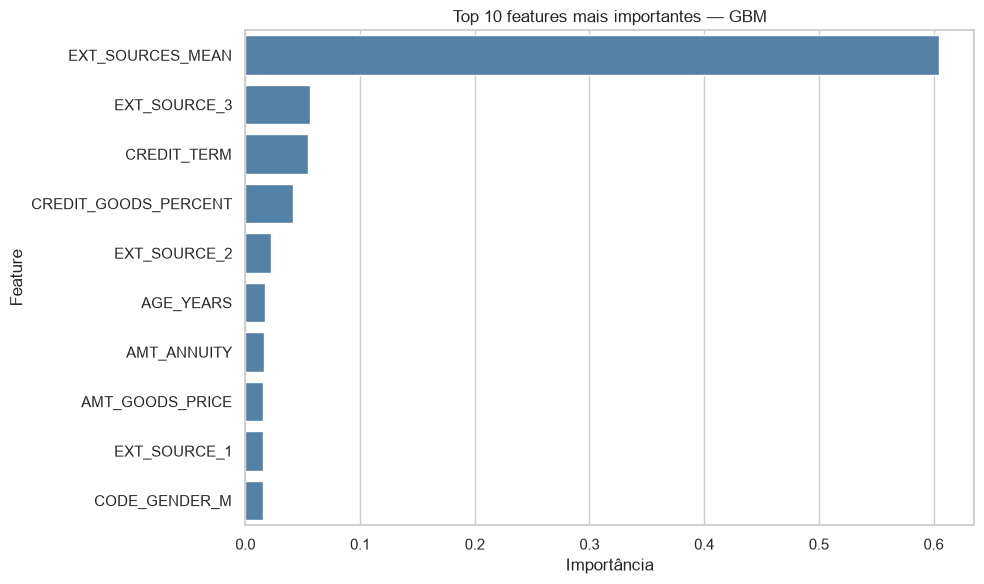

In [26]:
# Separa o alvo das variáveis explicativas e remove o identificador
X = ref_data.drop(columns=["TARGET", "SK_ID_CURR"], errors="ignore")
y = ref_data["TARGET"]

colunas_numericas = [
    coluna for coluna in X.columns
    if is_numeric_dtype(X[coluna])
]
colunas_categoricas = [
    coluna for coluna in X.columns
    if coluna not in colunas_numericas
]

# Pré-processamento
preprocessador = ColumnTransformer(
    transformers=[
        (
            "numericas",
            SimpleImputer(strategy="median"),
            colunas_numericas,
        ),
        (
            "categoricas",
            Pipeline([
                ("imputacao", SimpleImputer(strategy="most_frequent")),
                ("codificacao", OneHotEncoder(handle_unknown="ignore")),
            ]),
            colunas_categoricas,
        ),
    ],
    verbose_feature_names_out=False,
)

# Pipeline com o modelo GBM
modelo = Pipeline([
    ("preprocessamento", preprocessador),
    ("gbm", GradientBoostingClassifier(random_state=42)),
])

modelo.fit(X, y)

# Extrai e exibe as 10 maiores importâncias
nomes_features = modelo.named_steps[
    "preprocessamento"
].get_feature_names_out()

importancias = pd.DataFrame({
    "feature": nomes_features,
    "importancia": modelo.named_steps["gbm"].feature_importances_,
})

top_10 = importancias.nlargest(10, "importancia").sort_values("importancia", ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=top_10, x="importancia", y="feature", color="steelblue")
plt.title("Top 10 features mais importantes — GBM")
plt.xlabel("Importância")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [28]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

auc_scores = cross_val_score(
    estimator=modelo,  # Pipeline de pré-processamento + GBM
    X=X,
    y=y,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1,
)

print("AUC ROC por fold:", auc_scores)
print(f"AUC ROC média: {auc_scores.mean():.4f}")
print(f"Desvio padrão: {auc_scores.std():.4f}")

AUC ROC por fold: [0.75489532 0.75262263 0.75658763 0.75636968 0.75602026]
AUC ROC média: 0.7553
Desvio padrão: 0.0015


| Feature no top 10 | Origem no conjunto bruto | Significado e interpretação |
|---|---|---|
| `EXT_SOURCES_MEAN` | `EXT_SOURCE_1`, `EXT_SOURCE_2`, `EXT_SOURCE_3` | Média dos escores normalizados de fontes externas. É uma feature derivada; o dicionário não identifica quais são essas fontes. |
| `EXT_SOURCE_3` | `EXT_SOURCE_3` | Escore normalizado de uma fonte externa. |
| `CREDIT_TERM` | `AMT_ANNUITY`, `AMT_CREDIT` | Razão `AMT_ANNUITY / AMT_CREDIT`, criada no projeto como prazo implícito do empréstimo. |
| `CREDIT_GOODS_PERCENT` | `AMT_CREDIT`, `AMT_GOODS_PRICE` | Razão `AMT_CREDIT / AMT_GOODS_PRICE`; compara o valor do crédito ao preço do bem. |
| `EXT_SOURCE_2` | `EXT_SOURCE_2` | Escore normalizado de uma fonte externa. |
| `AGE_YEARS` | `DAYS_BIRTH` | Idade em anos, calculada como `-DAYS_BIRTH / 365`; no dicionário, `DAYS_BIRTH` é a idade do cliente em dias na data da solicitação. |
| `AMT_ANNUITY` | `AMT_ANNUITY` | Valor da anuidade/parcela do empréstimo. |
| `AMT_GOODS_PRICE` | `AMT_GOODS_PRICE` | Para empréstimos ao consumidor, preço do bem financiado. |
| `EXT_SOURCE_1` | `EXT_SOURCE_1` | Escore normalizado de uma fonte externa. |
| `CODE_GENDER_M` | `CODE_GENDER` | Categoria `M` de `CODE_GENDER` — gênero do cliente — codificada pelo `OneHotEncoder`. |

### 2.4 Análise Descritiva das Variáveis mais Importantes

In [ ]:
cat_var = ["CODE_GENDER"]

num_var = [
    "EXT_SOURCE_1",
    "EXT_SOURCE_2",
    "EXT_SOURCE_3",
    "AMT_ANNUITY",
    "AMT_CREDIT",
    "AMT_GOODS_PRICE",
    "AGE_YEARS",
    "CREDIT_TERM",
    "CREDIT_GOODS_PERCENT",
    "EXT_SOURCES_MEAN",
]

df_features_estudo = ref_data[cat_var + num_var].copy()
df_features_estudo.head()

In [31]:
df_features_estudo.info()

<class 'pandas.DataFrame'>
RangeIndex: 246008 entries, 0 to 246007
Data columns (total 11 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   CODE_GENDER           246008 non-null  str    
 1   EXT_SOURCE_1          107413 non-null  float64
 2   EXT_SOURCE_2          245477 non-null  float64
 3   EXT_SOURCE_3          197203 non-null  float64
 4   AMT_ANNUITY           245998 non-null  float64
 5   AMT_CREDIT            246008 non-null  float64
 6   AMT_GOODS_PRICE       245787 non-null  float64
 7   AGE_YEARS             246008 non-null  float64
 8   CREDIT_TERM           245998 non-null  float64
 9   CREDIT_GOODS_PERCENT  245787 non-null  float64
 10  EXT_SOURCES_MEAN      245869 non-null  float64
dtypes: float64(10), str(1)
memory usage: 20.9 MB


In [38]:
percentual_nulos = (
    df_features_estudo.isna()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
    .rename("percentual_nulos")
    .to_frame()
)

display(percentual_nulos)

,percentual_nulos
EXT_SOURCE_1,56.337599
EXT_SOURCE_3,19.838786
EXT_SOURCE_2,0.215847
AMT_GOODS_PRICE,0.089834
CREDIT_GOODS_PERCENT,0.089834
EXT_SOURCES_MEAN,0.056502
AMT_ANNUITY,0.004065
CREDIT_TERM,0.004065
CODE_GENDER,0.000000
AMT_CREDIT,0.000000


In [48]:
df_features_estudo.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
CODE_GENDER,246008,3,F,161887,NaN,NaN,NaN,NaN,NaN,NaN,NaN
EXT_SOURCE_1,107413.0,NaN,NaN,NaN,0.50165,0.211413,0.014568,0.333105,0.505446,0.674781,0.951624
EXT_SOURCE_2,245477.0,NaN,NaN,NaN,0.514303,0.191126,0.0,0.392155,0.565913,0.663593,0.855
EXT_SOURCE_3,197203.0,NaN,NaN,NaN,0.510871,0.194771,0.000527,0.37065,0.535276,0.669057,0.89601
AMT_ANNUITY,245998.0,NaN,NaN,NaN,27108.089708,14520.904087,1615.5,16510.5,24903.0,34596.0,258025.5
AMT_CREDIT,246008.0,NaN,NaN,NaN,599338.249368,402725.773305,45000.0,270000.0,514777.5,808650.0,4050000.0
AMT_GOODS_PRICE,245787.0,NaN,NaN,NaN,538652.98041,369595.049962,40500.0,238500.0,450000.0,679500.0,4050000.0
AGE_YEARS,246008.0,NaN,NaN,NaN,43.916482,11.953066,20.517808,33.975342,43.134247,53.89863,69.120548
CREDIT_TERM,245998.0,NaN,NaN,NaN,0.053652,0.022451,0.022073,0.0369,0.05,0.06391,0.12443
CREDIT_GOODS_PERCENT,245787.0,NaN,NaN,NaN,1.122987,0.123942,0.15,1.0,1.1188,1.198,6.0


In [46]:
proporcao_gender = (
    ref_data["CODE_GENDER"]
    .value_counts(normalize=True, dropna=False)
    .mul(100)
    .rename("percentual")
    .to_frame()
)

proporcao_gender["quantidade"] = ref_data["CODE_GENDER"].value_counts(
    dropna=False
)

display(proporcao_gender)

,percentual,quantidade
CODE_GENDER,,
F,65.805584,161887
M,34.193603,84119
XNA,0.000813,2


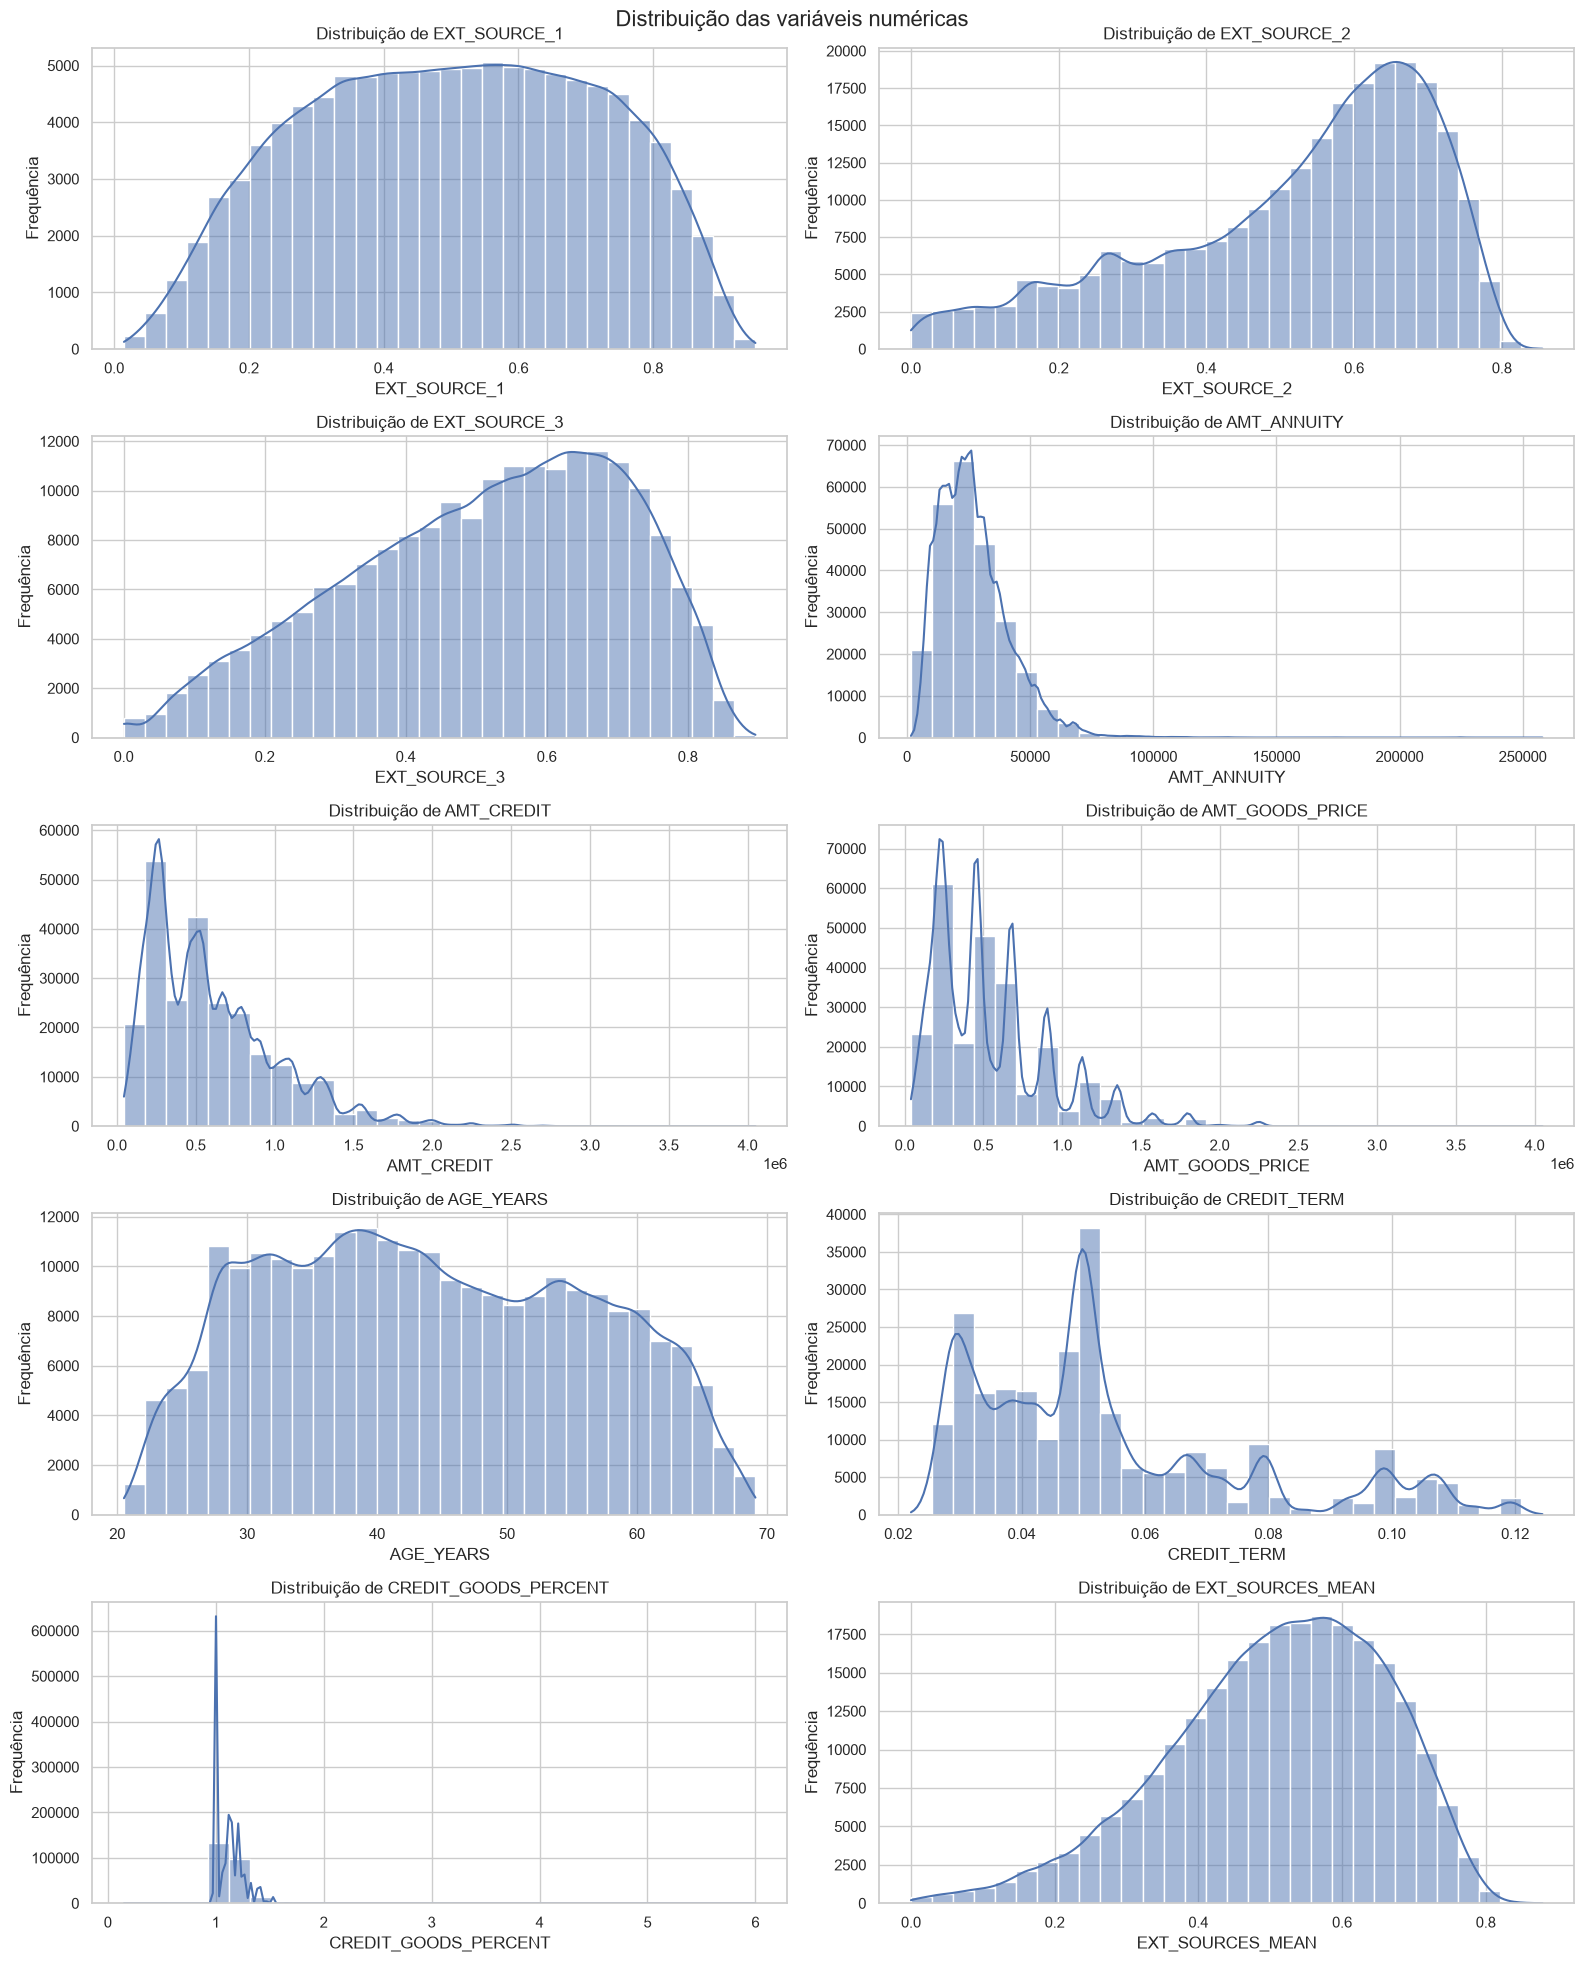

In [50]:
import math
import matplotlib.pyplot as plt
import seaborn as sns

n_colunas = 2
n_linhas = math.ceil(len(num_var) / n_colunas)

fig, axes = plt.subplots(
    n_linhas,
    n_colunas,
    figsize=(16, 4 * n_linhas),
)
axes = axes.flatten()

for i, variavel in enumerate(num_var):
    sns.histplot(
        data=df_features_estudo,
        x=variavel,
        bins=30,
        kde=True,
        ax=axes[i],
    )
    axes[i].set_title(f"Distribuição de {variavel}")
    axes[i].set_xlabel(variavel)
    axes[i].set_ylabel("Frequência")

# Remove os eixos vazios, se houver
for ax in axes[len(num_var):]:
    fig.delaxes(ax)

fig.suptitle("Distribuição das variáveis numéricas", fontsize=16)
fig.tight_layout()
plt.show()

### 2.5 Premissas para Geração dos Dados Sintéticos (Simulação do Drift)

A partir da análise exploratória das features mais importantes para o modelo GBM, a seguinte narrativa foi assumida:

> *Após ampliar a aquisição digital, a fintech passou a receber uma carteira de solicitantes mais jovens. Essa população pede empréstimos de maior valor, enquanto o preço declarado do bem cresce menos, elevando o crédito em relação ao bem. As solicitações também apresentam escores externos disponíveis ligeiramente menores. A simulação testa se essas mudanças alteram as distribuições de entrada e as previsões do modelo*

Para simular esse cenário, assumiremos as seguintes premissas:
1. **“Mais jovem” significa mudar a distribuição de idades, não reduzir dez anos de todo mundo sem restrição.**
A referência tem idade mínima de aproximadamente 20,5 anos. Subtrair dez anos de cada observação criaria idades próximas de 10,5 anos, incompatíveis com uma população adulta solicitando crédito. O cenário deve mirar uma mediana em torno de 33 anos, preservar o limite adulto e evitar acumular muitos clientes exatamente no limite. A coluna bruta correspondente é `DAYS_BIRTH`, que armazena idade em dias negativos; `AGE_YEARS` deve ser recalculada a partir dela.
2. **“Empréstimos maiores” não significa necessariamente bens mais caros na mesma proporção.**
`AMT_CREDIT` representa o valor do crédito. `AMT_GOODS_PRICE`, no dicionário, é o preço do bem para empréstimos ao consumidor. Se o crédito crescer mais do que esse preço, `CREDIT_GOODS_PERCENT` aumenta. Por exemplo, a combinação de crescimento de 20% no crédito e 5% no preço do bem elevaria a razão mediana de aproximadamente 1,12 para perto de 1,28. Isso descreve crédito maior em relação ao preço registrado, mas o dicionário não explica a razão dessa diferença; não devemos atribuí-la a taxas, seguros ou despesas sem outra evidência.
3. **A parcela acompanha o crédito, mas um pouco menos.**
Propus +15% em `AMT_ANNUITY` contra +20% em `AMT_CREDIT` para representar maior principal com crescimento proporcionalmente menor na parcela. Isso faz `CREDIT_TERM` cair um pouco. Apesar do nome usado no projeto, essa divisão não revela o prazo contratual em meses; no cenário, interprete-a somente como parcela relativa ao valor do crédito.
4. **“Escores menores” é uma hipótese sobre os valores, não uma interpretação garantida pelo dicionário.**
O Home Credit descreve `EXT_SOURCE_1`, `EXT_SOURCE_2` e `EXT_SOURCE_3` apenas como escores normalizados de fontes externas. Não documenta a fonte nem afirma que uma pontuação menor seja sempre pior. A narrativa pode dizer que os valores dos escores disponíveis caíram. Para chamar isso de “sinal menos favorável”, precisamos confirmar que essa direção é coerente com os dados e com a resposta do modelo.
5. **A feature agregada deve permanecer consistente com seus componentes.**
Não alteraria `EXT_SOURCES_MEAN` diretamente. Primeiro mudaria os escores brutos e depois recalcularia a média. O mesmo vale para `AGE_YEARS`, `CREDIT_TERM` e `CREDIT_GOODS_PERCENT`: são derivadas, então devem ser recalculadas das colunas de origem.
6. **`CODE_GENDER_M` fica fora do choque principal.**
Ela apareceu entre as dez features mais importantes, mas isso não torna necessário alterar a distribuição por gênero. O cenário já tem uma história coerente com idade, valores do empréstimo, preço do bem e escores externos. Manter `CODE_GENDER` estável ajuda a não misturar uma hipótese demográfica adicional.

## 3. Geração/Carga do Dataset Sintético

O dataset simula dados de clientes de uma **fintech de crédito**, conforme cenário hipotético identificado na etapa 2 acima.

In [51]:
# Encontra a raiz do projeto, esteja o notebook na raiz ou em notebooks/
project_root = Path.cwd()
if not (project_root / "data" / "processed").exists():
    project_root = project_root.parent

colunas = ["TARGET", *num_var]
processed_dir = project_root / "data" / "processed"

prod_periodo1 = pd.read_csv(
    processed_dir / "prod_periodo1_estavel.csv",
    usecols=colunas,
)

prod_periodo2 = pd.read_csv(
    processed_dir / "prod_periodo2_drift.csv",
    usecols=colunas,
)

In [53]:
for nome, df in [
    ("prod_periodo1", prod_periodo1),
    ("prod_periodo2", prod_periodo2),
]:
    print(f"\n{nome}")
    print(f"Linhas: {df.shape[0]:,}")
    print(f"Colunas: {df.shape[1]}")
    print(f"Nomes das colunas: {df.columns.tolist()}")


prod_periodo1
Linhas: 30,752
Colunas: 11
Nomes das colunas: ['TARGET', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'CREDIT_TERM', 'CREDIT_GOODS_PERCENT', 'AGE_YEARS', 'EXT_SOURCES_MEAN']

prod_periodo2
Linhas: 30,751
Colunas: 11
Nomes das colunas: ['TARGET', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'CREDIT_TERM', 'CREDIT_GOODS_PERCENT', 'AGE_YEARS', 'EXT_SOURCES_MEAN']


## 4. Visão Geral dos Dados

Analisamos a estrutura, tipos e estatísticas descritivas dos datasets

In [59]:
# Estatísticas descritivas por grupo (referência vs produção)
colunas = ["TARGET", *num_var]

print("=" * 60)
print("REFERÊNCIA (treinamento)")
print("=" * 60)
display(ref_data[colunas].describe().round(2).T)

print("\n" + "=" * 60)
print("PRODUÇÃO (com drift)")
print("=" * 60)
display(prod_periodo2.describe().round(2).T)

REFERÊNCIA (treinamento)


,count,mean,std,min,25%,50%,75%,max
TARGET,246008.0,0.08,0.27,0.00,0.00,0.00,0.00,1.00
EXT_SOURCE_1,107413.0,0.50,0.21,0.01,0.33,0.51,0.67,0.95
EXT_SOURCE_2,245477.0,0.51,0.19,0.00,0.39,0.57,0.66,0.85
EXT_SOURCE_3,197203.0,0.51,0.19,0.00,0.37,0.54,0.67,0.90
AMT_ANNUITY,245998.0,27108.09,14520.90,1615.50,16510.50,24903.00,34596.00,258025.50
AMT_CREDIT,246008.0,599338.25,402725.77,45000.00,270000.00,514777.50,808650.00,4050000.00
AMT_GOODS_PRICE,245787.0,538652.98,369595.05,40500.00,238500.00,450000.00,679500.00,4050000.00
AGE_YEARS,246008.0,43.92,11.95,20.52,33.98,43.13,53.90,69.12
CREDIT_TERM,245998.0,0.05,0.02,0.02,0.04,0.05,0.06,0.12
CREDIT_GOODS_PERCENT,245787.0,1.12,0.12,0.15,1.00,1.12,1.20,6.00



PRODUÇÃO (com drift)


,count,mean,std,min,25%,50%,75%,max
TARGET,30751.0,0.12,0.32,0.00,0.00,0.00,0.00,1.00
AMT_CREDIT,30751.0,719075.75,482516.63,54000.00,324000.00,621000.00,970380.00,4860000.00
AMT_ANNUITY,30749.0,31288.31,16663.05,2644.42,19049.18,28809.22,39997.57,264685.72
AMT_GOODS_PRICE,30727.0,565817.77,388359.00,47250.00,250425.00,472500.00,713475.00,4252500.00
EXT_SOURCE_1,13369.0,0.43,0.18,0.02,0.29,0.43,0.58,0.80
EXT_SOURCE_2,30683.0,0.44,0.16,0.00,0.33,0.48,0.56,0.73
EXT_SOURCE_3,24599.0,0.43,0.17,0.00,0.32,0.46,0.57,0.75
CREDIT_TERM,30749.0,0.05,0.02,0.02,0.04,0.05,0.06,0.12
CREDIT_GOODS_PERCENT,30727.0,1.28,0.14,0.26,1.14,1.28,1.37,3.43
AGE_YEARS,30751.0,33.61,7.19,19.83,27.68,33.10,39.61,48.66


## 5. Comparação Visual das Distribuições Numéricas

Utilizaremos os histogramas de cada feature numérica para visualizar o drift entre a referência e a produção.

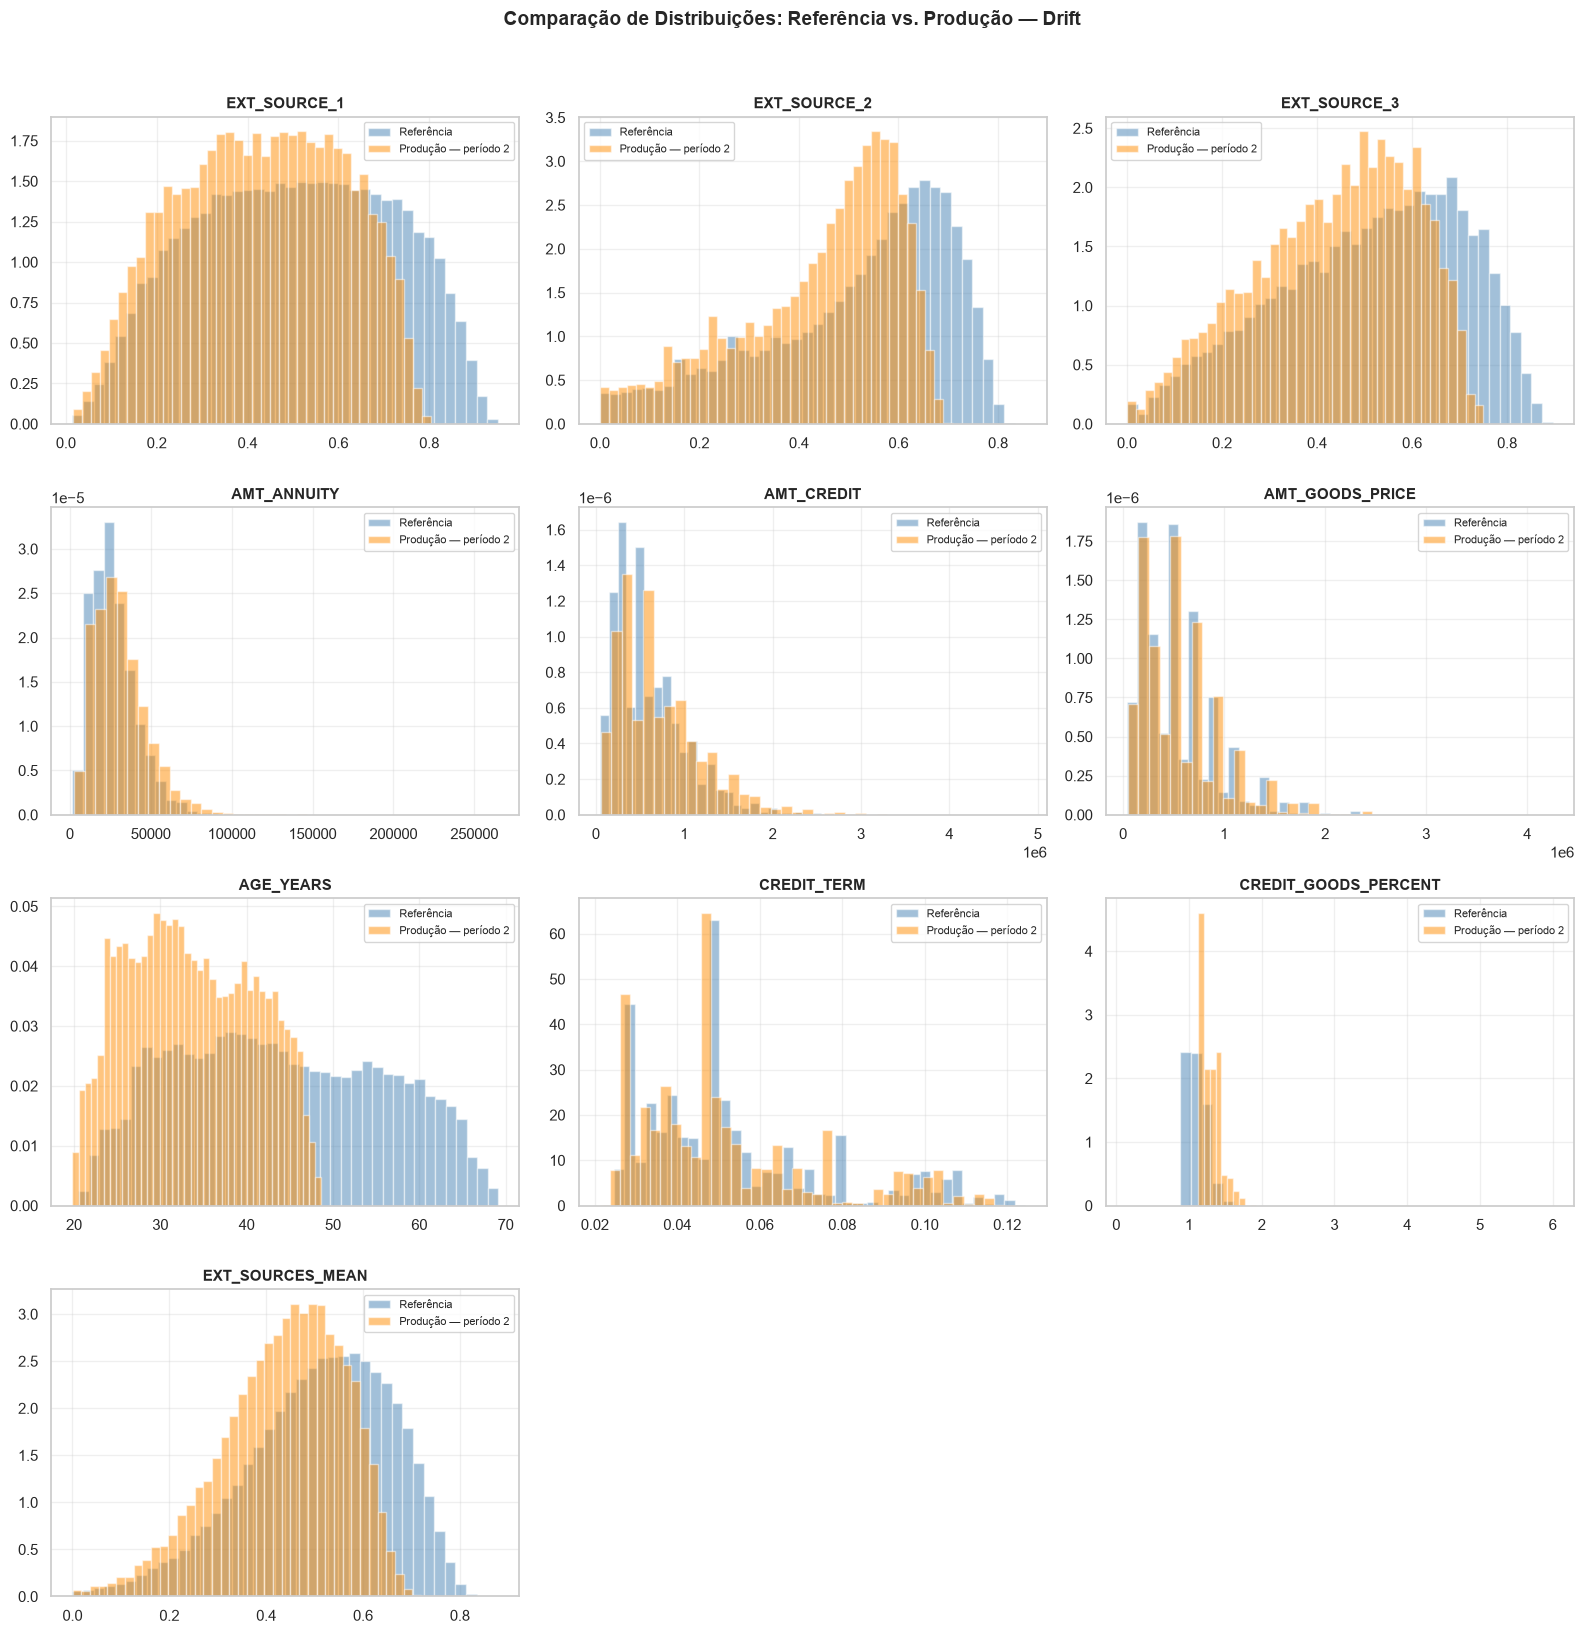

In [61]:
fig, axes = plt.subplots(4, 3, figsize=(16, 16))
axes = axes.ravel()

for i, col in enumerate(num_var):
    ax = axes[i]

    ax.hist(
        ref_data[col].dropna(),
        bins=40,
        alpha=0.5,
        density=True,
        label="Referência",
        color="steelblue",
        edgecolor="white",
    )
    ax.hist(
        prod_periodo2[col].dropna(),
        bins=40,
        alpha=0.5,
        density=True,
        label="Produção — período 2",
        color="darkorange",
        edgecolor="white",
    )

    ax.set_title(col, fontsize=11, fontweight="bold")
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

for j in range(len(num_var), len(axes)):
    axes[j].set_visible(False)

fig.suptitle(
    "Comparação de Distribuições: Referência vs. Produção — Drift",
    fontsize=14,
    fontweight="bold",
    y=1.02,
)
fig.tight_layout()
plt.show()

### 5.1 Gráfico de Densidade (KDE)

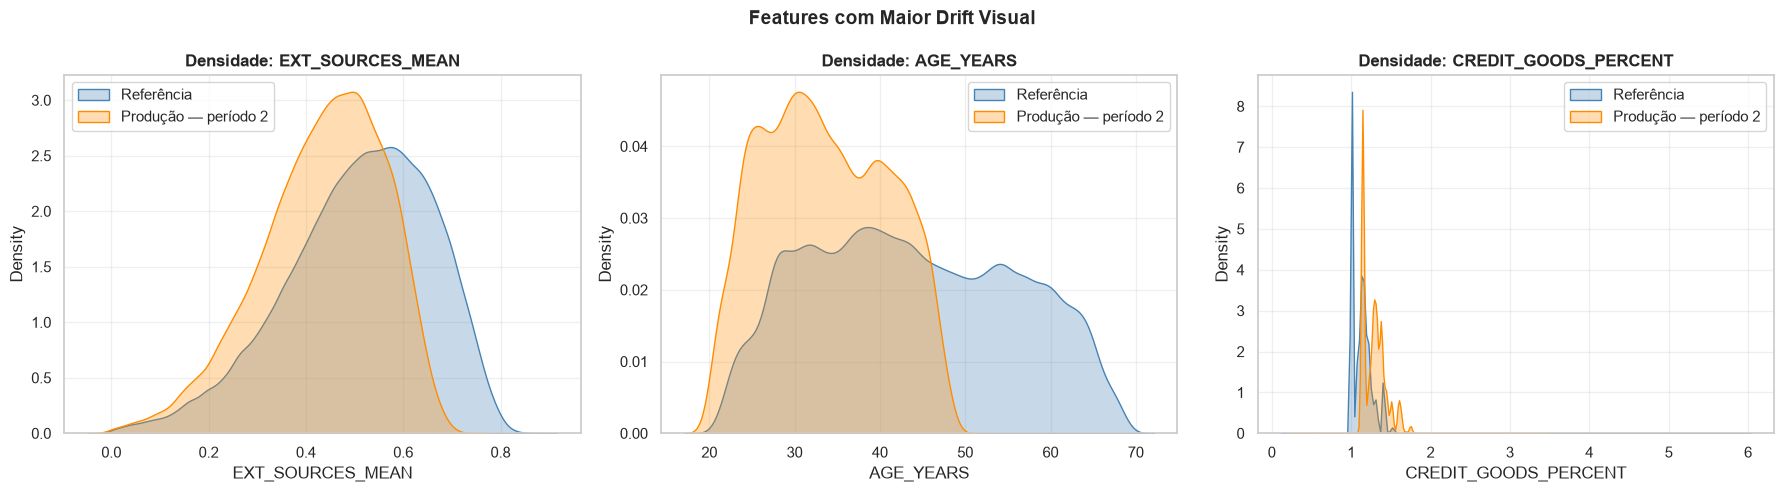

In [62]:
features = ["EXT_SOURCES_MEAN", "AGE_YEARS", "CREDIT_GOODS_PERCENT"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, col in zip(axes, features):
    sns.kdeplot(
        data=ref_data,
        x=col,
        ax=ax,
        label="Referência",
        color="steelblue",
        fill=True,
        alpha=0.3,
    )
    sns.kdeplot(
        data=prod_periodo2,
        x=col,
        ax=ax,
        label="Produção — período 2",
        color="darkorange",
        fill=True,
        alpha=0.3,
    )

    ax.set_title(f"Densidade: {col}", fontsize=12, fontweight="bold")
    ax.legend()
    ax.grid(True, alpha=0.3)

fig.suptitle("Features com Maior Drift Visual", fontsize=14, fontweight="bold")
fig.tight_layout()
plt.show()

### 5.2 Boxplots Comparativos

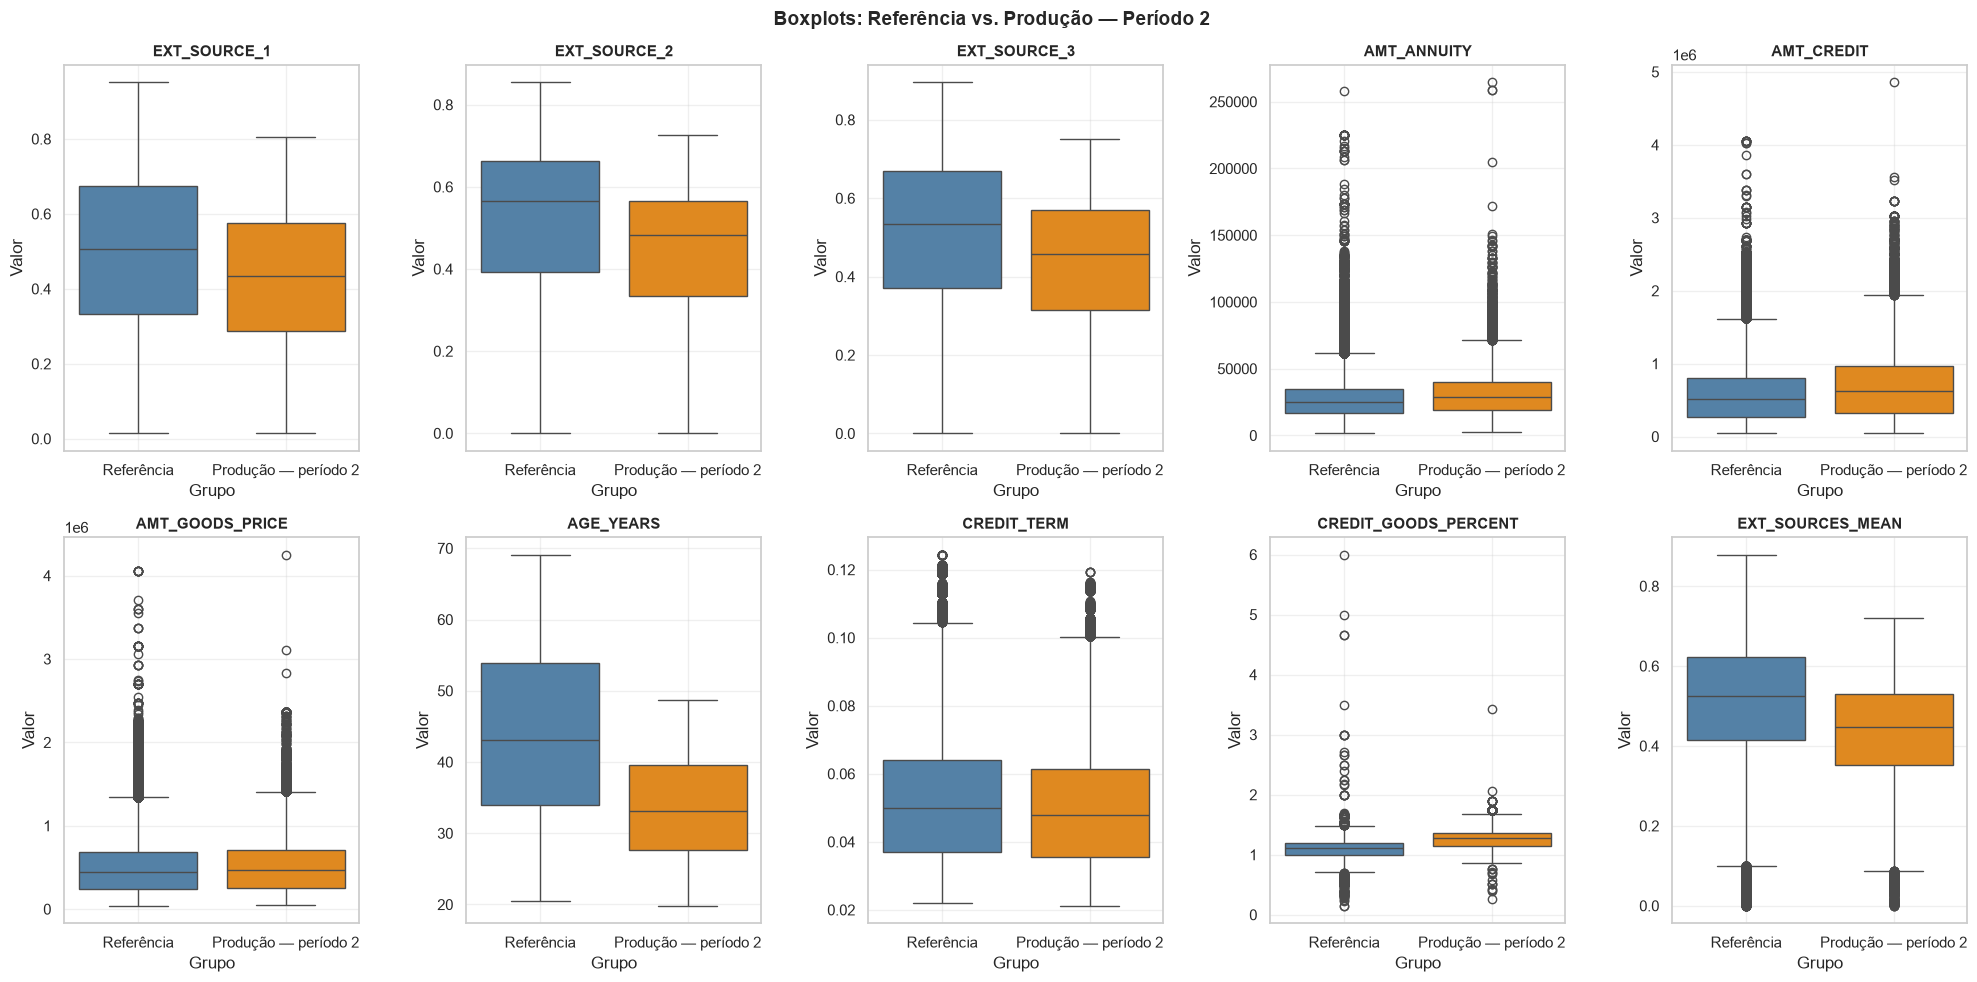

In [63]:
fig, axes = plt.subplots(2, 5, figsize=(20, 10))
axes = axes.ravel()

for i, col in enumerate(num_var):
    ax = axes[i]

    data_box = pd.DataFrame({
        "Valor": pd.concat(
            [ref_data[col], prod_periodo2[col]],
            ignore_index=True,
        ),
        "Grupo": (
            ["Referência"] * len(ref_data)
            + ["Produção — período 2"] * len(prod_periodo2)
        ),
    })

    sns.boxplot(
        data=data_box,
        x="Grupo",
        y="Valor",
        ax=ax,
        hue="Grupo",
        palette={
            "Referência": "steelblue",
            "Produção — período 2": "darkorange",
        },
        legend=False,
    )

    ax.set_title(col, fontsize=11, fontweight="bold")
    ax.grid(True, alpha=0.3)

fig.suptitle(
    "Boxplots: Referência vs. Produção — Período 2",
    fontsize=14,
    fontweight="bold",
)
fig.tight_layout()
plt.show()

### 5.3 Correlação entre Features

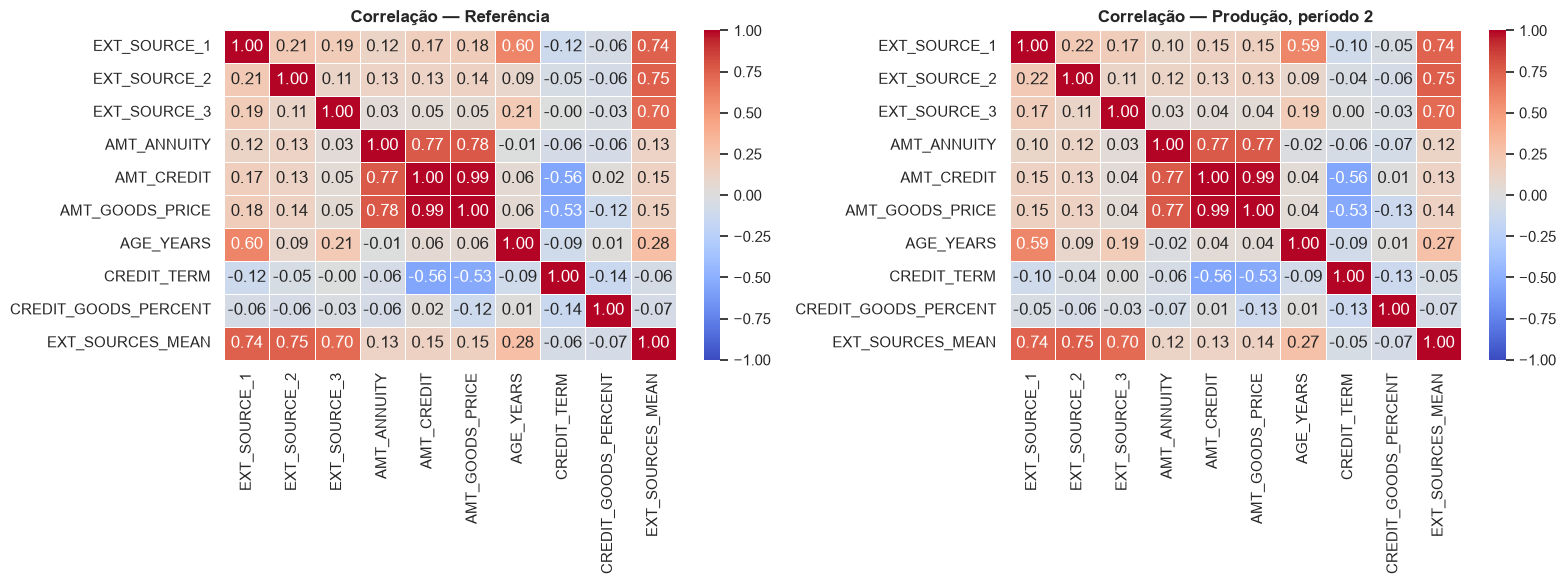

In [64]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Referência
corr_ref = ref_data[num_var].corr()
sns.heatmap(
    corr_ref,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    ax=axes[0],
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5,
)
axes[0].set_title("Correlação — Referência", fontsize=12, fontweight="bold")

# Produção — período 2
corr_prod = prod_periodo2[num_var].corr()
sns.heatmap(
    corr_prod,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    ax=axes[1],
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5,
)
axes[1].set_title(
    "Correlação — Produção, período 2",
    fontsize=12,
    fontweight="bold",
)

fig.tight_layout()
plt.show()

## 6. Tabela Resumo de Diferenças

In [65]:
summary = pd.DataFrame({
    "Ref (μ)": ref_data[num_var].mean(),
    "Prod período 2 (μ)": prod_periodo2[num_var].mean(),
    "Δ μ": prod_periodo2[num_var].mean() - ref_data[num_var].mean(),
    "Ref (σ)": ref_data[num_var].std(),
    "Prod período 2 (σ)": prod_periodo2[num_var].std(),
    "Δ σ": prod_periodo2[num_var].std() - ref_data[num_var].std(),
}).round(2)

print("Diferenças entre Referência e Produção — Período 2:")
display(summary)

Diferenças entre Referência e Produção — Período 2:


,Ref (μ),Prod período 2 (μ),Δ μ,Ref (σ),Prod período 2 (σ),Δ σ
EXT_SOURCE_1,0.50,0.43,-0.07,0.21,0.18,-0.03
EXT_SOURCE_2,0.51,0.44,-0.08,0.19,0.16,-0.03
EXT_SOURCE_3,0.51,0.43,-0.08,0.19,0.17,-0.03
AMT_ANNUITY,27108.09,31288.31,4180.22,14520.90,16663.05,2142.15
AMT_CREDIT,599338.25,719075.75,119737.50,402725.77,482516.63,79790.85
AMT_GOODS_PRICE,538652.98,565817.77,27164.78,369595.05,388359.00,18763.95
AGE_YEARS,43.92,33.61,-10.30,11.95,7.19,-4.76
CREDIT_TERM,0.05,0.05,-0.00,0.02,0.02,-0.00
CREDIT_GOODS_PERCENT,1.12,1.28,0.16,0.12,0.14,0.02
EXT_SOURCES_MEAN,0.51,0.43,-0.08,0.15,0.13,-0.02


## 7. Distribuição do Target (default)

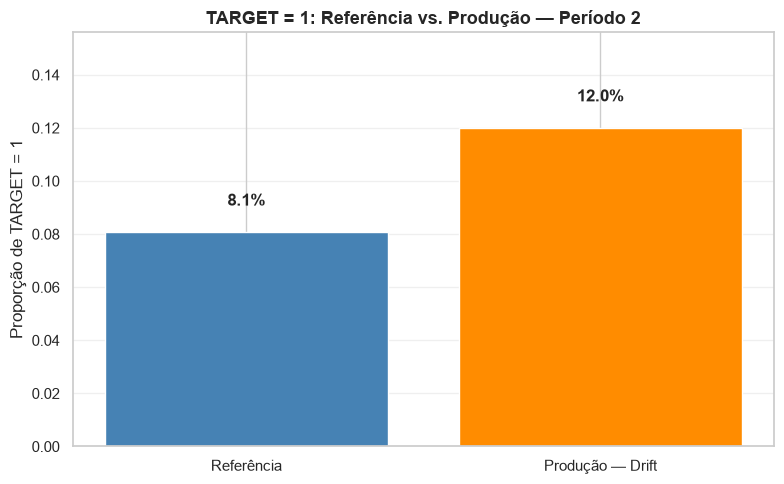

In [67]:
fig, ax = plt.subplots(figsize=(8, 5))

labels = ["Referência", "Produção — Drift"]
rates = [
    ref_data["TARGET"].mean(),
    prod_periodo2["TARGET"].mean(),
]

bars = ax.bar(
    labels,
    rates,
    color=["steelblue", "darkorange"],
    edgecolor="white",
)

for bar, rate in zip(bars, rates):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.01,
        f"{rate:.1%}",
        ha="center",
        fontsize=12,
        fontweight="bold",
    )

ax.set_ylabel("Proporção de TARGET = 1")
ax.set_title(
    "TARGET = 1: Referência vs. Produção — Período 2",
    fontsize=13,
    fontweight="bold",
)
ax.set_ylim(0, max(rates) * 1.3)
ax.grid(True, alpha=0.3, axis="y")

fig.tight_layout()
plt.show()

## 8. Considerações Finais

Neste notebook, exploramos visualmente o dataset de crédito e identificamos evidencias claras de **Data Drift** nas principais features do modelo GBM. Essa avaliação permitiu validar o script `data-drift-simulation.py` que sintetiza os dados drifitados.